# Agents, Session 6A: Building Multi-Agent Systems with LangChain

## Launch week at DilSeTrips

DilSeTrips' support inbox gets three kinds of message all day:

- "Hi, how are you?" (general chat)
- "What stays do you have in Old Manali?" (stays and prices)
- "What's your cancellation policy?" (rules about refunds)

And, more and more often, all three in one message:

> "hi, how are you? i have a couple of questions. what is the price of Snow Valley Cottage per night? and if we cancel our 3-night River Bend Homestay booking 5 days before check-in, how much money do we get back?"

Today we build a support desk out of several small agents, three different ways, and see which one answers that message best:

1. **Centralized:** one boss agent sends each part to the right expert.
2. **Decentralized:** no boss; experts pass the message along until someone takes it.
3. **Hybrid:** a light router splits the message, and the experts also talk to each other.

These are the three architectures from Session 5. The question to keep asking: **who decides, and who talks to whom?**

In Session 6B, you'll meet CrewAI, a framework that does much of today's coordination work for you.

### Setup

This notebook works in **Google Colab** and in **VS Code**. Your Gemini key can live in either place:

- **Colab:** click the key icon in the left sidebar, add a secret named `GOOGLE_API_KEY`, paste your key, and switch on "Notebook access".
- **VS Code:** create a file named `.env` next to this notebook containing `GOOGLE_API_KEY=your-key` (see `.env.example`).

If neither is set up, the setup cell simply asks you to paste the key. The whole notebook makes about 40 calls to Gemini; each call waits its turn so we stay within the free tier.

In [ ]:
%pip install -q "langchain>=1.0" "langchain-google-genai>=4.0,<4.4" requests python-dotenv

*Why `<4.4`? Newer versions of the Gemini package need a version of Google's library that CrewAI (Session 6B) can't use. Staying below 4.4 lets both notebooks share one environment in VS Code.*

The setup cell looks for your key in three places, in order: Colab Secrets, then a `.env` file, then it asks you. `try` / `except` means "try this; if it fails, carry on": `google.colab` only exists on Colab, so in VS Code that step fails quietly and we move on.

In [ ]:
import os
import requests
from getpass import getpass
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain.agents import create_agent

try:
    from google.colab import userdata                        # only exists on Colab
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception:
    from dotenv import load_dotenv
    load_dotenv(".env")                                       # VS Code: read the .env file next to this notebook
if not os.getenv("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

# At most 4 model calls a minute (the free tier allows 5), shared by every agent in this notebook
limiter = InMemoryRateLimiter(requests_per_second=4 / 60, check_every_n_seconds=0.5, max_bucket_size=1)
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", rate_limiter=limiter)

print(llm.invoke("Say hello to a class in five words.").text)

### One small helper: `ask`

We'll run many agents today. To keep every cell short, here is one helper function that:

1. sends a message to an agent,
2. prints each tool the agent used, labelled with the agent's name, so you can watch it work,
3. counts how many times it called the model (each answer the model writes is one call),
4. returns the agent's final answer as text.

Set `show_tools=False` when you don't want an agent's tools printed (we'll use that for the boss, whose hand-offs are announced another way).

You've seen everything in it before: an agent returns a dictionary with a list of `"messages"`, and the last message is the answer.

In [ ]:
usage = {"model_calls": 0}    # a running total of model calls for the whole notebook

def ask(agent, text, name="agent", step_limit=25, show_tools=True):
    """Send text to an agent, show the tools it used, and return its final answer."""
    result = agent.invoke({"messages": [{"role": "user", "content": text}]},
                          config={"recursion_limit": step_limit})
    for message in result["messages"]:
        if message.type == "ai":                      # every AI message is one model call
            usage["model_calls"] = usage["model_calls"] + 1
            if show_tools:
                for call in message.tool_calls:
                    print(f"      [{name}] used {call['name']}({call['args']})")
    return result["messages"][-1].text

print("ask() is ready")

## 1. Why LangChain for multi-agent systems

You've used LangChain since the RAG module. Four things make it useful for a team of agents:

- **LLM integration:** every agent uses the same `llm` object.
- **Easy tools:** any Python function with a docstring can become a tool.
- **Memory:** an agent remembers a conversation if we keep its messages and send them again (Session 3).
- **Small, swappable parts:** each agent is one `create_agent(...)` call, so we can build three architectures from the same parts.

*A note on older code: tutorials often use `initialize_agent`, `AgentType`, `Tool(...)` and `ConversationBufferMemory`. Those no longer exist in LangChain 1.x. Everything they did is now `create_agent`.*

## 2. Warm-up: one agent with tools and memory

Before a team, one good agent: a model, two tools and a memory. Both tools are free and need no key.

In [ ]:
def get_weather_forecast(place: str) -> str:
    """Get the weather forecast for the next 7 days for a town, for example Manali.

    Args:
        place: The town or city.
    """
    found = requests.get("https://geocoding-api.open-meteo.com/v1/search", params={"name": place, "count": 1}).json()
    if "results" not in found:
        return f"Could not find {place}."
    town = found["results"][0]
    forecast = requests.get("https://api.open-meteo.com/v1/forecast", params={
        "latitude": town["latitude"], "longitude": town["longitude"], "timezone": "auto",
        "daily": "temperature_2m_min,temperature_2m_max"}).json()["daily"]
    lines = []
    for day in range(len(forecast["time"])):
        lines.append(f"{forecast['time'][day]}: {forecast['temperature_2m_min'][day]} to {forecast['temperature_2m_max'][day]} C")
    return f"Forecast for {town['name']}: " + "; ".join(lines)

print(get_weather_forecast("Manali")[:120])

In [ ]:
def search_travel_guide(place: str) -> str:
    """Read the Wikivoyage travel guide for a place: what to see, do and eat.

    Args:
        place: The name of the place, for example Old Manali.
    """
    response = requests.get("https://en.wikivoyage.org/w/api.php",
                            params={"action": "query", "prop": "extracts", "explaintext": 1,
                                    "redirects": 1, "titles": place, "format": "json"},
                            headers={"User-Agent": "GenAI-course-notebook/1.0"})
    pages = response.json()["query"]["pages"]
    for page_id in pages:
        if "extract" in pages[page_id]:
            return pages[page_id]["extract"][:3000]
    return f"No guide found for {place}."

print(search_travel_guide("Old Manali")[:120])

Now the agent. For memory, we keep the conversation in an ordinary Python list called `conversation`, and send the whole list every time. That's short-term memory from Session 3: the model itself remembers nothing; our list does.

In [ ]:
travel_agent = create_agent(
    model=llm,
    tools=[get_weather_forecast, search_travel_guide],
    system_prompt="You are DilSeTrips' travel assistant. Use your tools for facts. Answer in under 80 words.",
)

conversation = []      # the agent's memory: every message so far

conversation.append({"role": "user", "content": "What's the weather in Manali this week?"})
result = travel_agent.invoke({"messages": conversation})
conversation = result["messages"]          # keep everything, including the agent's answer
print("Turn 1:", conversation[-1].text, "\n")

conversation.append({"role": "user", "content": "And what should we not miss there?"})
result = travel_agent.invoke({"messages": conversation})
conversation = result["messages"]
print("Turn 2:", conversation[-1].text)

In turn 2, "there" means Manali only because we sent turn 1 again with it. Try it: set `conversation = []` just before the second question, and the agent no longer knows where "there" is. Each turn is a ReAct loop (Session 4): the model thinks, calls a tool, reads the result, and answers.

*Watch out in older demo code for `print(response.content)` after `agent.invoke(...)`. The result is a dictionary, not a message, so that line fails. The answer is `result["messages"][-1].text`.*

## 3. Centralized: one boss, three experts

**Architecture:** centralized. **Pattern:** manager/worker. One **orchestrator** reads every message and decides which expert handles each part.

First, DilSeTrips' data. This is **pretend data** for the exercise; in a real company it would come from a database.

In [ ]:
stays = {
    "Snow Valley Cottage": {"place": "Old Manali", "price_per_night": 3200, "notes": "very quiet, pure-veg kitchen"},
    "River Bend Homestay": {"place": "Old Manali", "price_per_night": 2400, "notes": "quiet, beside the river"},
    "Coffee Estate Cottage": {"place": "Coorg", "price_per_night": 4400, "notes": "quiet, estate walks"},
}

policies = {
    "cancellation": "Cancel 7 or more days before check-in: 80% refund. 2 to 6 days before: 50% refund. Less than 2 days: no refund.",
    "changes": "You can change your dates once for free, up to 7 days before check-in.",
}
print("Data ready:", list(stays.keys()))

Two tools read that data: one for stays, one for policies.

In [ ]:
def search_stays(query: str) -> str:
    """Search DilSeTrips stays by place or stay name. Returns prices per night.

    Args:
        query: A place (e.g. Old Manali), a stay name, or 'all'.
    """
    lines = []
    for name in stays:
        stay = stays[name]
        if query.lower() == "all" or query.lower() in name.lower() or query.lower() in stay["place"].lower():
            lines.append(f"{name} ({stay['place']}): Rs {stay['price_per_night']} per night, {stay['notes']}")
    if len(lines) == 0:
        return "No match. Our stays are: " + ", ".join(stays.keys())
    return "\n".join(lines)

def look_up_policy(topic: str) -> str:
    """Look up a DilSeTrips policy: cancellation or changes.

    Args:
        topic: The policy topic, for example cancellation.
    """
    for name in policies:
        if name in topic.lower():
            return policies[name]
    return "Policies we have: " + ", ".join(policies.keys())

print(search_stays("Old Manali"))
print(look_up_policy("cancellation"))

Now the three **workers**. Each is a separate agent with its own job and its own tool. The general expert has no tool: it just chats.

In [ ]:
stays_expert = create_agent(model=llm, tools=[search_stays],
    system_prompt="You are DilSeTrips' stays expert. Answer only about stays and prices, using search_stays. Two sentences.")

policy_expert = create_agent(model=llm, tools=[look_up_policy],
    system_prompt="You are DilSeTrips' policy expert. Answer only about cancellations and changes, using look_up_policy. Two sentences.")

general_expert = create_agent(model=llm, tools=[],
    system_prompt="You are DilSeTrips' friendly support. Greet warmly and help with general questions. Two sentences.")

print("Three workers ready.")

How does the boss send work to a worker? The simplest trick in LangChain is **agents as tools**: wrap each worker in an ordinary function, and give those functions to the boss as its tools. When the boss calls `ask_stays_expert`, that function runs the stays agent.

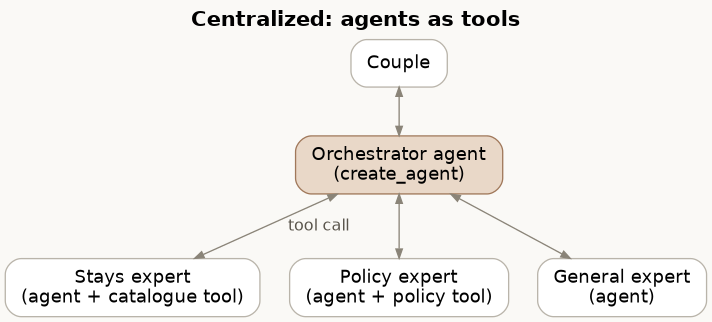

*The orchestrator's only tools are the three workers. Every message goes in and out through it.*

In [ ]:
def ask_stays_expert(question: str) -> str:
    """Ask the stays expert about stays, places and prices per night.

    Args:
        question: The part of the customer's message about stays.
    """
    print(f"   boss -> stays expert: {question}")
    return ask(stays_expert, question, name="stays expert")

def ask_policy_expert(question: str) -> str:
    """Ask the policy expert about cancellations, refunds and date changes.

    Args:
        question: The part of the customer's message about policies.
    """
    print(f"   boss -> policy expert: {question}")
    return ask(policy_expert, question, name="policy expert")

def ask_general_expert(question: str) -> str:
    """Ask the general expert to handle greetings and general questions.

    Args:
        question: The greeting or general part of the customer's message.
    """
    print(f"   boss -> general expert: {question}")
    return ask(general_expert, question, name="general expert")

Now the boss. Its **system prompt holds the routing rules**, so it knows which expert gets what.

In [ ]:
orchestrator_rules = """You are the orchestrator of DilSeTrips customer support.
Send each part of the customer's message to the right expert, then combine their answers.
- Stays, places, prices: ask_stays_expert
- Cancellations, changes, refunds: ask_policy_expert
- Greetings and anything general: ask_general_expert
Do not answer from your own knowledge. If a message has several parts, ask each relevant expert."""

orchestrator = create_agent(model=llm, tools=[ask_stays_expert, ask_policy_expert, ask_general_expert],
                            system_prompt=orchestrator_rules)
print("Orchestrator ready.")

*Older course code builds routing rules like these but never passes them to the agent, so the boss routes by guesswork. Rules only work if the agent can see them: here, through `system_prompt=`.*

Let's try two simple questions, each needing just one expert.

**Before you run it:** how many model calls will a simple "Hi" cost?

In [ ]:
for question in ["Hi, how are you?", "What is your cancellation policy for homestays?"]:
    calls_before = usage["model_calls"]
    print("Customer:", question)
    print("Desk:", ask(orchestrator, question, show_tools=False))
    print(f"   ({usage['model_calls'] - calls_before} model calls)\n")

Even a greeting costs about three calls: the boss decides, the expert answers, and the boss passes the answer on. Central control has a price.

### The step limit

An agent's loop has a **step limit**. The session plan's code calls it `max_iterations`: it sets it to 2, shows the boss failing on a three-part question, then raises it to 4. In today's LangChain the setting is called `recursion_limit` and it counts *steps*: calling the model is one step and running its tools is another, so one iteration is about two steps.

So `max_iterations=2` is about `recursion_limit=4`, and `max_iterations=4` is about `recursion_limit=9`.

**Before you run it:** with a limit of 4 steps, will the boss manage all three parts?

In [ ]:
multi_part = ("hi, how are you? i have a couple of questions. what is the price of Snow Valley Cottage per night? "
              "and if we cancel our 3-night River Bend Homestay booking 5 days before check-in, how much money do we get back?")

try:
    print(ask(orchestrator, multi_part, step_limit=4, show_tools=False))
except Exception as error:                 # the agent stops with an error when it runs out of steps
    print("STOPPED:", error)

Usually it stops. (If it succeeded, look at the `boss ->` lines: Gemini asked all three experts in one step.) Now with room to work:

In [ ]:
calls_before = usage["model_calls"]
centralized_answer = ask(orchestrator, multi_part, step_limit=9, show_tools=False)
centralized_calls = usage["model_calls"] - calls_before
print("\nDesk:", centralized_answer)
print(f"   ({centralized_calls} model calls)")

Look at the refund part. The policy expert knows the rule (5 days before means 50% back), but not what the couple paid: only the stays expert knows River Bend's price. In this design experts never talk to each other, so the boss must notice the gap and do the sum itself. Often the answer stops at "50% of what you paid". Remember this for the hybrid desk.

## 4. Decentralized: pass it along

**Architecture:** decentralized. There is **no boss**. A message arrives at one expert, who decides *for itself* whether it's theirs. If yes, it answers; if not, it passes the message to the next expert. The general expert is the last resort.

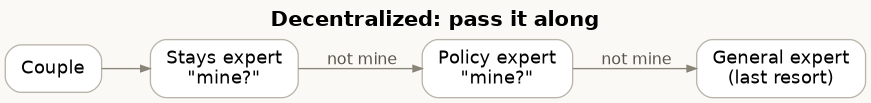

*Each expert asks itself "is this mine?" and either answers or passes the message on.*

Each expert's decision is a small yes/no question to the model. We ask for the answer in a fixed shape using **structured output** (Session 2): we describe the shape as a JSON schema, and the model must fill it in.

In [ ]:
# The shape of each expert's decision: a yes/no, and a short reason
decision_schema = {
    "title": "decision",
    "description": "Whether this expert should answer the message",
    "type": "object",
    "properties": {
        "handle_it": {"type": "boolean"},
        "reason": {"type": "string"},
    },
    "required": ["handle_it", "reason"],
}

# The experts, in the order the message travels
peers = [
    {"name": "Stays expert", "agent": stays_expert, "expertise": "stays, places and prices"},
    {"name": "Policy expert", "agent": policy_expert, "expertise": "cancellations, changes and refunds"},
    {"name": "General expert", "agent": general_expert, "expertise": "greetings and anything else"},
]
print("Decision shape and peers ready.")

The desk itself is a simple `for` loop over the experts, so a message can never go round in circles.

In [ ]:
def decentralized_desk(message):
    for position in range(len(peers)):
        peer = peers[position]
        if position == len(peers) - 1:                    # the last expert always answers
            print(f"   {peer['name']}: last resort, I'll answer.")
            return ask(peer["agent"], message, name=peer["name"])
        question = (f"You are DilSeTrips' {peer['name']}. Your expertise: {peer['expertise']}. "
                    f"Decide only for yourself: should YOU answer this message?\n\nMessage: {message}")
        decision = llm.with_structured_output(decision_schema).invoke(question)
        usage["model_calls"] = usage["model_calls"] + 1
        if decision["handle_it"]:
            print(f"   {peer['name']}: mine ({decision['reason']})")
            return ask(peer["agent"], message, name=peer["name"])
        print(f"   {peer['name']}: not mine ({decision['reason']}), passing it on")

print("Desk:", decentralized_desk("What is your cancellation policy for homestays?"))

The stays expert looked, decided it wasn't its question, and passed it on; the policy expert took it. No boss was needed, and if one expert broke, the others would keep working.

Now the three-part message.

**Before you run it:** which expert will answer, and what happens to the other two parts?

In [ ]:
calls_before = usage["model_calls"]
decentralized_answer = decentralized_desk(multi_part)
decentralized_calls = usage["model_calls"] - calls_before
print("\nDesk:", decentralized_answer)
print(f"   ({decentralized_calls} model calls)")

The first expert to see the message (stays) finds a part it can answer, says "mine", and answers only that part. Nobody greets the couple, and the refund question is lost, because once an expert takes a message, nobody else sees it. Each agent has only a **local view**, and no one checks that the **whole** message was answered.

How could a team of equals handle a multi-part message? The session plan lists six approaches. Discuss them before reading the verdicts:

| Approach | How it works | Verdict |
|---|---|---|
| 1. Multi-turn sequential | The first agent answers its part, asks "shall I continue?", then passes the rest | Not recommended: the user does the coordinating |
| 2. Split and process in parallel | A query analyser splits the message; each part goes to its agent | Workable, but the analyser is a hidden boss |
| 3. Chain of responsibility with memory | Each agent answers what it can, notes what's left, and passes the rest on | A good decentralized option (homework) |
| 4. Master coordinator | A coordinator splits, calls each agent, combines | That's the centralized desk again |
| 5. Collaborative decision | All agents see the message, claim parts, then one combines | Powerful, but many calls |
| 6. Hybrid | A light router only splits; agents do the work and talk directly | The best balance: we build it next |

## 5. Hybrid: a light router, and experts who talk to each other

**Architecture:** hybrid. The **router** does one small job: split the message into parts and label each with an expert. It doesn't answer anything. Then each expert works on its own part, and **an expert that needs information from another expert asks it directly**, without going through the router.

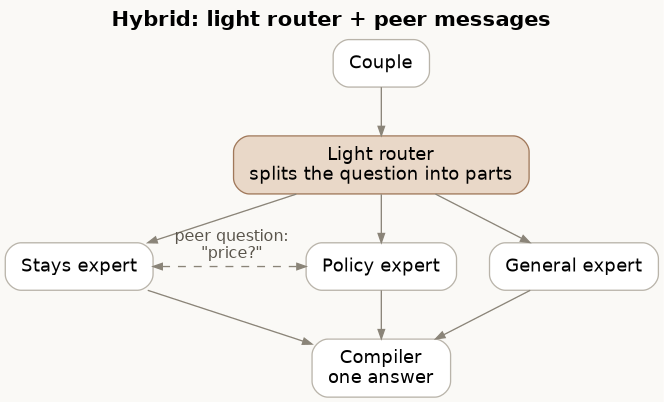

*The router only splits the message. The policy expert asks the stays expert for a price directly.*

To make that possible, the policy expert gets two new tools. The first does the refund sum **in code**, so the model never does arithmetic in its head.

In [ ]:
def calculate_refund(price_per_night: int, nights: int, days_before_check_in: int) -> str:
    """Calculate a cancellation refund exactly, using DilSeTrips' cancellation policy.

    Args:
        price_per_night: Price per night in rupees.
        nights: Number of nights booked.
        days_before_check_in: How many days before check-in they cancel.
    """
    paid = price_per_night * nights
    if days_before_check_in >= 7:
        percent = 80
    elif days_before_check_in >= 2:
        percent = 50
    else:
        percent = 0
    refund = paid * percent / 100
    return f"Paid Rs {paid}; cancelling {days_before_check_in} days before gives {percent}% back: Rs {refund:.0f}"

print(calculate_refund(2400, 3, 5))

The second tool lets the policy expert **message the stays expert directly**: a peer-to-peer conversation, with no router or boss in between.

In [ ]:
def ask_stays_peer(question: str) -> str:
    """Ask the stays expert directly for a stay's price or details.

    Args:
        question: What you need to know, e.g. 'price per night of River Bend Homestay'.
    """
    print(f"      policy expert -> stays expert: {question}")
    return ask(stays_expert, question, name="stays expert")

policy_expert_with_peers = create_agent(
    model=llm,
    tools=[look_up_policy, ask_stays_peer, calculate_refund],
    system_prompt=("You are DilSeTrips' policy expert. Use look_up_policy for rules. If you need a stay's price, "
                   "ask the stays expert with ask_stays_peer. Always use calculate_refund for money. Two sentences."))
print("Policy expert, now with a teammate to ask, is ready.")

The router's answer also has a fixed shape: a list of parts, each with an expert's name and the words that belong to it.

In [ ]:
router_schema = {
    "title": "routing",
    "description": "The parts of a message, and which expert handles each",
    "type": "object",
    "properties": {
        "parts": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "expert": {"type": "string", "enum": ["stays", "policy", "general"]},
                    "part": {"type": "string", "description": "That part of the message, in the customer's words"},
                },
                "required": ["expert", "part"],
            },
        },
    },
    "required": ["parts"],
}

hybrid_experts = {"stays": stays_expert, "policy": policy_expert_with_peers, "general": general_expert}
print("Router shape ready.")

The hybrid desk in three steps: **split** (one call), **answer each part** (the experts, who may ask each other), **combine** (one call).

In [ ]:
def hybrid_desk(message):
    # 1. Split: the router labels each part with an expert, and answers nothing
    routing = llm.with_structured_output(router_schema).invoke(
        "Split this customer message into its separate parts and label each with an expert. "
        "Do not answer anything.\n\nMessage: " + message)
    usage["model_calls"] = usage["model_calls"] + 1

    # 2. Answer each part with its expert
    answers = ""
    for item in routing["parts"]:
        print(f"   router -> {item['expert']} expert: {item['part']}")
        answer = ask(hybrid_experts[item["expert"]], item["part"], name=item["expert"] + " expert")
        answers = answers + f"[{item['expert']}] {answer}\n"

    # 3. Combine everything into one reply
    reply = llm.invoke(f"Customer's message: {message}\n\nExperts' answers:\n{answers}\n"
                       "Combine these into one short, warm reply. Keep every number exactly as given.")
    usage["model_calls"] = usage["model_calls"] + 1
    return reply.text

In [ ]:
calls_before = usage["model_calls"]
hybrid_answer = hybrid_desk(multi_part)
hybrid_calls = usage["model_calls"] - calls_before
print("\nDesk:", hybrid_answer)
print(f"   ({hybrid_calls} model calls)")

Read the printed lines from top to bottom: the router split the message three ways; the general expert greeted; the stays expert gave Snow Valley's price; and the policy expert, needing River Bend's price, **asked the stays expert directly**, then let code do the sum: Rs 2,400 × 3 nights = Rs 7,200, and 50% back is Rs 3,600.

(The policy expert's own `used ...` lines appear after its conversation with the stays expert, because an agent's steps are printed when it finishes.)

That direct message between experts is what makes this a hybrid, not just a centralized desk with a different name.

## 6. The same message, three desks

Which desk answered best, and at what cost? We check each answer for the two numbers that matter: Rs 3,200 (Snow Valley's price) and Rs 3,600 (the refund).

In [ ]:
def mentions(text, options):
    """True if text contains any of the options."""
    for option in options:
        if option in text:
            return True
    return False

results = [
    ["Centralized", centralized_answer, centralized_calls],
    ["Decentralized", decentralized_answer, decentralized_calls],
    ["Hybrid", hybrid_answer, hybrid_calls],
]
print(f"{'Desk':14s} {'Price?':>7s} {'Refund?':>8s} {'Calls':>6s}")
for name, answer, calls in results:
    has_price = mentions(answer, ["3,200", "3200"])
    has_refund = mentions(answer, ["3,600", "3600"])
    print(f"{name:14s} {str(has_price):>7s} {str(has_refund):>8s} {calls:>6d}")

A typical run: the **decentralized** desk is cheapest but answers one part. The **centralized** desk answers more, but the refund amount depends on the boss noticing the missing price. The **hybrid** desk gets both numbers right, because the router gave every part an owner and the policy expert could ask its peer. It isn't the cheapest: correctness costs a few more calls.

## 7. How patterns fit architectures

**Design patterns** describe how agents interact; **architectures** describe how the system is organised.

| Pattern | What it is | Fits best in | Why |
|---|---|---|---|
| Manager/worker | A boss delegates to specialised workers | Centralized or hybrid | Clear control |
| Peer/swarm | Equals following local rules | Decentralized | Robust, no single point of failure |
| Pipeline | Each step hands its result to the next | Centralized or hybrid | Something must enforce the order |
| Specialists | Agents with deep domain knowledge | Hybrid | Efficient for multi-part tasks |

### What LangChain left us doing by hand

Look back at what you wrote: the `ask_` wrapper functions, the peer list and its loop, the router shape, the combining step. LangChain gave us excellent agents; **the teamwork between them was all our own code.** That's the gap **CrewAI** fills in Session 6B: you describe the team and its tasks, and CrewAI runs the coordination.

## 8. Homework

1. **[Easy] A fourth worker.** Add a weather expert to the centralized desk, using `get_weather_forecast`. What did you have to change: the worker, its `ask_` function, the routing rules? Did any other worker change?
2. **[Easy] Step limits.** Run the multi-part message with step limits 4, 6, 9 and 12. When did Gemini call the experts together, and when one at a time?
3. **[Medium] Cheaper decisions.** Every hop in the decentralized desk costs a model call just to ask "is this mine?". Could a simple keyword check skip the obvious cases? Careful: a check for "stays" also matches "homestays" in a cancellation question.
4. **[Medium] Approach 3.** Change `decentralized_desk` so each expert answers only its part and passes the *rest* of the message on. Does it now answer all three parts? How many calls does it use compared with the hybrid desk?

## Quick reference

| Idea | Code |
|---|---|
| One agent | `create_agent(model=llm, tools=[...], system_prompt="...")` |
| Memory across turns | keep the messages in a list and send the whole list each turn |
| Agents as tools | a function that calls `ask(other_agent, question)` |
| Step limit | `config={"recursion_limit": N}`; the run stops with an error when it's reached |
| Structured output | `llm.with_structured_output(schema).invoke(prompt)` returns a dictionary |
| Money in code | a tool like `calculate_refund`, never the model's arithmetic |